# 04 — Random Forest: classificação de área queimada por aprendizado de máquina

**Projeto:** Área queimada no Parque Nacional da Chapada das Mesas (MA), estação seca de 2024
**Bootcamp:** Space Tech Bootcamp 2026 — Future Tech Leaders Brasil

Nos notebooks 02 e 03, a regra para dizer "queimado" foi escolhida por nós: **um índice maior que um limiar** (0,20). Aqui testamos o caminho alternativo sugerido pelo Emanuel: um **Random Forest**, que **aprende a regra sozinho** a partir das suas amostras.

### Como funciona o Random Forest
- Damos ao modelo **exemplos** de pixels queimados e não queimados (as suas amostras do notebook 02).
- Cada pixel é descrito por **várias variáveis ao mesmo tempo**: o NBR de cada mês, a queda de NBR de cada mês, o dNBR acumulado e o dNBR mensal máximo.
- O modelo cria **muitas árvores de decisão** (aqui, 100). Cada uma aprende regras um pouco diferentes, e o resultado final é a **votação** entre elas.
- Vantagem: ele pode combinar informações, por exemplo "a queda foi grande **e** o NBR depois ficou muito baixo", algo que um limiar simples não faz.

### O que este notebook faz
1. Monta as **variáveis** para cada pixel.
2. Carrega as **amostras** do Drive e, opcionalmente, permite **acrescentar casos difíceis** (recomendado).
3. **Treina** o Random Forest e confere a acurácia num conjunto de teste.
4. **Classifica** o parque e aplica a mesma conectividade dos outros métodos.
5. **Compara os três métodos com o MapBiomas**: limiar acumulado, limiar mensal e Random Forest.

> Execute **célula por célula** (Shift + Enter). **Não use "Executar tudo"**, porque a Etapa 3 tem desenho opcional.

## Etapa 0 — Conexão e Google Drive

In [1]:
!pip install -q geemap

In [2]:
import ee

PROJETO = 'lirun-94f92'
ee.Authenticate()
ee.Initialize(project=PROJETO)
print('Earth Engine conectado ao projeto:', PROJETO)

Earth Engine conectado ao projeto: lirun-94f92


In [3]:
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os, json, shutil, urllib.request
from IPython.display import Image, display
from google.colab import drive

drive.mount('/content/drive')
PASTA = '/content/drive/MyDrive/area-queimada-chapada-mesas'
ARQ_Q = f'{PASTA}/amostras_queimado.geojson'
ARQ_N = f'{PASTA}/amostras_nao_queimado.geojson'
os.makedirs('resultados/figuras', exist_ok=True)
os.makedirs('resultados/tabelas', exist_ok=True)
print('Amostras no Drive:',
      'QUEIMADO ✅' if os.path.exists(ARQ_Q) else 'QUEIMADO ❌',
      '|', 'NÃO QUEIMADO ✅' if os.path.exists(ARQ_N) else 'NÃO QUEIMADO ❌')

Mounted at /content/drive
Amostras no Drive: QUEIMADO ✅ | NÃO QUEIMADO ✅


## Etapa 1 — Parâmetros

In [4]:
ANO = 2024
MES_ANTES = 5
MESES = [6, 7, 8, 9, 10]
LIMIAR = 0.20                  # para os métodos de limiar (comparação)
MIN_PIXELS = 3
LIMIAR_NUVEM = 0.60
ESCALA = 20
N_ARVORES = 100                # número de árvores do Random Forest
PONTOS_POR_CLASSE = 1000       # pixels sorteados por classe para treino + teste
SEMENTE = 42
VARIAVEIS = 'mudanca'          # 'mudanca' (só quedas de NBR) ou 'todas'

MB_ANUAL = 'projects/mapbiomas-public/assets/brazil/fire/collection5/mapbiomas_fire_collection5_annual_burned_v1'
MB_MENSAL = 'projects/mapbiomas-public/assets/brazil/fire/collection5/mapbiomas_fire_collection5_monthly_burned_v1'
NOMES_MES = {5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago', 9: 'set', 10: 'out'}

## Etapa 2 — Variáveis para o Random Forest

Para cada pixel, montamos **13 variáveis**:
- `NBR_05` a `NBR_10`: o NBR de cada mês (6 variáveis);
- `dNBR_06` a `dNBR_10`: a queda de NBR de cada mês (5 variáveis);
- `dNBR_acum`: o dNBR acumulado (maio − outubro);
- `dNBR_max`: o dNBR mensal máximo.

**Por que `VARIAVEIS = 'mudanca'`?** No primeiro teste (05/11), com as 13 variáveis, a mais importante foi o **NBR de maio**, ou seja, **antes** das queimadas. Como as amostras de queimado estavam concentradas em poucos lugares do parque, o modelo aprendeu a **vegetação de cada região**, e não a marca do fogo (viés amostral espacial). Resultado: Dice de 0,19. Agora usamos **só as 7 variáveis de mudança** (as quedas de NBR), que descrevem o que aconteceu, e não onde. Para repetir o primeiro teste, troque para `VARIAVEIS = 'todas'` na Etapa 1.

In [5]:
wdpa = ee.FeatureCollection('WCMC/WDPA/current/polygons')
parque = (wdpa.filter(ee.Filter.eq('ISO3', 'BRA'))
              .filter(ee.Filter.stringContains('NAME', 'Chapada Das Mesas')))
area = parque.geometry()
AREA_PARQUE = area.area(maxError=10).divide(1e4).getInfo()
print(f'Área do parque: {AREA_PARQUE:,.0f} ha')

s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
csplus = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')

def mascarar(img):
    return img.updateMask(img.select('cs_cdf').gte(LIMIAR_NUVEM)).select(['B4', 'B8A', 'B12'])

colecao = (s2.filterBounds(area)
             .filterDate(ee.Date.fromYMD(ANO, MES_ANTES, 1), ee.Date.fromYMD(ANO, max(MESES), 1).advance(1, 'month'))
             .linkCollection(csplus, ['cs_cdf'])
             .map(mascarar))

def composicao_mensal(mes):
    ini = ee.Date.fromYMD(ANO, mes, 1)
    comp = colecao.filterDate(ini, ini.advance(1, 'month')).median()
    nbr = comp.normalizedDifference(['B8A', 'B12']).rename('NBR')
    return comp.addBands(nbr).clip(area)

comps = {m: composicao_mensal(m) for m in [MES_ANTES] + MESES}
nbr = {m: comps[m].select('NBR') for m in comps}
dnbr_mes = {m: nbr[m - 1].subtract(nbr[m]).rename('dNBR') for m in MESES}
dnbr_acum = nbr[MES_ANTES].subtract(nbr[max(MESES)]).rename('dNBR_acum')
dnbr_max = ee.ImageCollection([dnbr_mes[m] for m in MESES]).max().rename('dNBR_max')

variaveis = ee.Image.cat(
    [nbr[m].rename(f'NBR_{m:02d}') for m in [MES_ANTES] + MESES] +
    [dnbr_mes[m].rename(f'dNBR_{m:02d}') for m in MESES] +
    [dnbr_acum, dnbr_max])
if VARIAVEIS == 'mudanca':
    BANDAS = ['dNBR_06', 'dNBR_07', 'dNBR_08', 'dNBR_09', 'dNBR_10', 'dNBR_acum', 'dNBR_max']
    variaveis = variaveis.select(BANDAS)
else:
    BANDAS = variaveis.bandNames().getInfo()
print(f'Variáveis usadas ({len(BANDAS)}):', BANDAS)

Área do parque: 160,638 ha
Variáveis usadas (7): ['dNBR_06', 'dNBR_07', 'dNBR_08', 'dNBR_09', 'dNBR_10', 'dNBR_acum', 'dNBR_max']


## Etapa 3 — Amostras

As amostras do notebook 02 são carregadas do Drive.

### Por que acrescentar casos difíceis (opcional, mas recomendado)
As suas amostras atuais cobrem **só casos fáceis**: o miolo vermelho-escuro das cicatrizes e áreas bege puras. Um modelo treinado só com isso aprende a separar o "muito fácil" e pode errar justamente nos **casos do meio**, como:
- **bordas** das cicatrizes e queimadas mais fracas (devem ser **queimado**);
- áreas que **só secaram**, do verde para o amarelo, sem escurecer (devem ser **não queimado**). Foi isso que inflou o mês de junho.

**Se quiser acrescentar** (cerca de 30 min), desenhe nos mapas abaixo:
- **Mapa A (queimado):** áreas **laranja** no dNBR máximo que, passando pelos meses na falsa-cor, **escureceram** em algum mês.
- **Mapa B (não queimado):** áreas **laranja-claras** no dNBR máximo que só **amarelaram**, sem escurecer.

**Se não quiser**, rode as células de guardar **sem desenhar nada**: o notebook usa só as amostras do Drive.

As amostras novas são **juntadas** às antigas e salvas no Drive.

In [6]:
def carregar(caminho):
    with open(caminho) as f:
        dados = json.load(f)
    if not dados.get('features'):
        return ee.FeatureCollection([])
    return ee.FeatureCollection([ee.Feature(f) for f in dados['features']])

def salvar(fc, caminho):
    with open(caminho, 'w') as f:
        json.dump(fc.getInfo(), f)
    print('Salvo no Drive:', caminho)

def pegar_desenhos(m):
    for nome in ['user_rois', '_user_rois']:
        fc = getattr(m, nome, None)
        if fc is not None:
            return ee.FeatureCollection(fc)
    dc = getattr(m, 'draw_control', None) or getattr(m, '_draw_control', None)
    if dc is not None and getattr(dc, 'collection', None) is not None:
        return ee.FeatureCollection(dc.collection)
    feats = getattr(m, 'draw_features', None)
    return ee.FeatureCollection(feats) if feats else ee.FeatureCollection([])

vis_falsa = {'bands': ['B12', 'B8A', 'B4'], 'min': 0, 'max': 3500}
vis_dnbr = {'min': -0.2, 'max': 0.6, 'palette': ['1a9850', 'ffffbf', 'fdae61', 'd73027', '67001f']}
contorno = ee.Image().paint(parque, 0, 2)

def mapa_base():
    m = geemap.Map(basemap='SATELLITE')
    m.centerObject(area, 10)
    for mes in [MES_ANTES] + MESES:
        m.addLayer(comps[mes], vis_falsa, f'Falsa-cor {NOMES_MES[mes]}', False)
    m.addLayer(dnbr_max, vis_dnbr, 'dNBR máximo (jun–out)')
    m.addLayer(contorno, {'palette': 'white'}, 'Limite do parque')
    return m

print('Pronto. Rode a próxima célula para abrir o Mapa A (opcional).')

Pronto. Rode a próxima célula para abrir o Mapa A (opcional).


### Mapa A — casos difíceis QUEIMADOS (opcional)

In [7]:
mapa_queimado = mapa_base()
mapa_queimado

Map(center=[-7.152470328340464, -47.14468685930818], controls=(WidgetControl(options=['position', 'transparent…

In [8]:
novos = pegar_desenhos(mapa_queimado).map(lambda f: f.set('classe', 1))
n_novos = novos.size().getInfo()
anteriores = carregar(ARQ_Q) if os.path.exists(ARQ_Q) else ee.FeatureCollection([])
amostras_queimado = anteriores.merge(novos) if n_novos > 0 else anteriores
if n_novos > 0:
    salvar(amostras_queimado, ARQ_Q)
print(f'QUEIMADO: {anteriores.size().getInfo()} do Drive + {n_novos} novos = {amostras_queimado.size().getInfo()} polígonos')

QUEIMADO: 18 do Drive + 0 novos = 18 polígonos


### Mapa B — casos difíceis NÃO QUEIMADOS (opcional)

In [9]:
mapa_nao_queimado = mapa_base()
mapa_nao_queimado

Map(center=[-7.152470328340464, -47.14468685930818], controls=(WidgetControl(options=['position', 'transparent…

In [10]:
novos = pegar_desenhos(mapa_nao_queimado).map(lambda f: f.set('classe', 0))
n_novos = novos.size().getInfo()
anteriores = carregar(ARQ_N) if os.path.exists(ARQ_N) else ee.FeatureCollection([])
amostras_nao_queimado = anteriores.merge(novos) if n_novos > 0 else anteriores
if n_novos > 0:
    salvar(amostras_nao_queimado, ARQ_N)
print(f'NÃO QUEIMADO: {anteriores.size().getInfo()} do Drive + {n_novos} novos = {amostras_nao_queimado.size().getInfo()} polígonos')

NÃO QUEIMADO: 20 do Drive + 0 novos = 20 polígonos


## Etapa 4 — Treino e teste do Random Forest

1. Sorteamos até **1.000 pixels por classe** dentro dos polígonos.
2. Separamos **70 %** para **treinar** e **30 %** para **testar**.
3. Treinamos o modelo e medimos a acurácia nos pixels de teste.

> **Atenção:** os pixels de teste vêm dos **mesmos polígonos** que os de treino, então essa acurácia é **otimista**. A avaliação independente é a comparação com o MapBiomas, na Etapa 6.

In [12]:
rotulo_q = ee.Image(1).byte().clip(amostras_queimado.geometry())
rotulo_n = ee.Image(0).byte().clip(amostras_nao_queimado.geometry())
rotulos = ee.ImageCollection([rotulo_n, rotulo_q]).mosaic().rename('classe')

pontos = variaveis.addBands(rotulos).stratifiedSample(
    numPoints=PONTOS_POR_CLASSE, classBand='classe',
    region=amostras_queimado.merge(amostras_nao_queimado).geometry(),
    scale=ESCALA, seed=SEMENTE, geometries=False, tileScale=4)
pontos = pontos.randomColumn('aleatorio', SEMENTE)
treino = pontos.filter(ee.Filter.lt('aleatorio', 0.7))
teste = pontos.filter(ee.Filter.gte('aleatorio', 0.7))

contagem = pontos.aggregate_histogram('classe').getInfo()
print('Pixels por classe (0 = não queimado, 1 = queimado):', contagem)
print('Treino:', treino.size().getInfo(), '| Teste:', teste.size().getInfo())

modelo = ee.Classifier.smileRandomForest(numberOfTrees=N_ARVORES, seed=SEMENTE).train(
    features=treino, classProperty='classe', inputProperties=BANDAS)

matriz = teste.classify(modelo).errorMatrix('classe', 'classification')
print(f'Acurácia no teste: {matriz.accuracy().getInfo() * 100:.1f}%')
print(f'Kappa no teste: {matriz.kappa().getInfo():.3f}')
print('Matriz de confusão [linhas = real, colunas = previsto]:', matriz.getInfo())

Pixels por classe (0 = não queimado, 1 = queimado): {'0': 1000, '1': 175}
Treino: 807 | Teste: 368
Acurácia no teste: 100.0%
Kappa no teste: 1.000
Matriz de confusão [linhas = real, colunas = previsto]: [[310, 0], [0, 58]]


### Quais variáveis o modelo mais usou?

A **importância** mostra quanto cada variável ajudou a separar as classes. É um ótimo slide: mostra **o que o modelo "olhou"** para decidir.

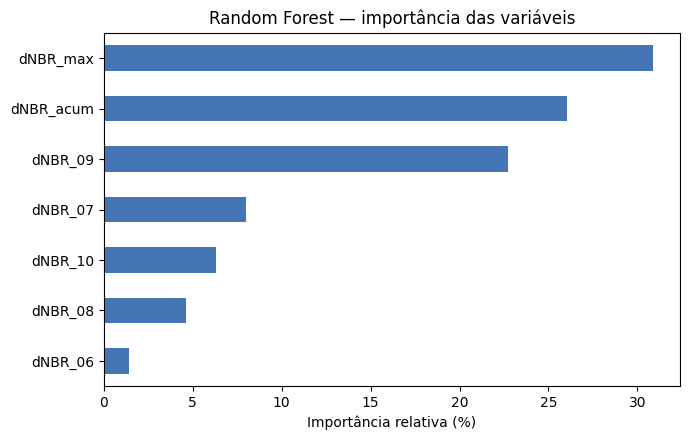

In [13]:
imp = modelo.explain().get('importance').getInfo()
importancia = pd.Series(imp).sort_values()
importancia = importancia / importancia.sum() * 100
importancia.round(1).to_csv(f'resultados/tabelas/rf_importancia_variaveis_{VARIAVEIS}.csv', header=['importância (%)'])

fig, ax = plt.subplots(figsize=(7, 4.5))
importancia.plot.barh(ax=ax, color='#4575b4')
ax.set_xlabel('Importância relativa (%)')
ax.set_title('Random Forest — importância das variáveis')
plt.tight_layout()
plt.savefig(f'resultados/figuras/rf_importancia_variaveis_{VARIAVEIS}.png', dpi=150)
plt.show()

## Etapa 5 — Classificação do parque

Aplicamos o modelo a **todos os pixels** do parque e o **mesmo filtro de conectividade** dos outros métodos (manchas com menos de 3 pixels são removidas).

In [14]:
def limpar(mascara):
    q = mascara.selfMask()
    tamanho = q.connectedPixelCount(maxSize=50, eightConnected=True)
    return q.updateMask(tamanho.gte(MIN_PIXELS)).rename('queimado')

def area_ha(mascara, escala=ESCALA):
    return ee.Image.pixelArea().divide(1e4).updateMask(mascara).reduceRegion(
        ee.Reducer.sum(), area, scale=escala, maxPixels=1e13, tileScale=4).get('area').getInfo() or 0.0

classif_rf = variaveis.classify(modelo).eq(1)
queimado_rf = limpar(classif_rf)
queimado_acum = limpar(dnbr_acum.gt(LIMIAR))
queimado_mensal = limpar(dnbr_max.gt(LIMIAR))

AREA_RF = area_ha(queimado_rf)
print(f'Random Forest: {AREA_RF:,.0f} ha queimados = {AREA_RF / AREA_PARQUE * 100:.1f}% do parque')

Random Forest: 1,382 ha queimados = 0.9% do parque


## Etapa 6 — Comparação dos três métodos com o MapBiomas

As mesmas métricas do notebook 03: **omissão**, **comissão** e **Dice**, contra o MapBiomas Fogo (queimadas de junho a outubro de 2024), numa grade de 30 m.

In [15]:
mb_mes = ee.Image(MB_MENSAL).select(f'burned_monthly_{ANO}').clip(area)
mb_periodo = mb_mes.gte(min(MESES)).And(mb_mes.lte(max(MESES))).selfMask()
ref = mb_periodo.unmask(0).gt(0)
AREA_MB = area_ha(mb_periodo, 30)

def validar(mascara):
    nosso = mascara.unmask(0).gt(0)
    codigo = nosso.multiply(2).add(ref).rename('codigo')
    soma = ee.Image.pixelArea().divide(1e4).addBands(codigo).reduceRegion(
        ee.Reducer.sum().group(groupField=1, groupName='codigo'),
        area, scale=30, maxPixels=1e13, tileScale=4)
    g = {int(x['codigo']): x['sum'] for x in soma.get('groups').getInfo()}
    vp, fn, fp = g.get(3, 0.0), g.get(1, 0.0), g.get(2, 0.0)
    return {'área (ha)': vp + fp,
            'omissão (%)': fn / (vp + fn) * 100 if vp + fn else np.nan,
            'comissão (%)': fp / (vp + fp) * 100 if vp + fp else np.nan,
            'Dice': 2 * vp / (2 * vp + fp + fn) if (2 * vp + fp + fn) else np.nan}

metodos = {
    'Limiar: dNBR acumulado (0,20)': queimado_acum,
    'Limiar: dNBR mensal máximo (0,20)': queimado_mensal,
    'Random Forest': queimado_rf,
}
linhas = []
for nome, m in metodos.items():
    r = {'método': nome, **validar(m)}
    linhas.append(r)
    print(f"{nome:36s} {r['área (ha)']:>9,.0f} ha | omissão {r['omissão (%)']:5.1f}% | "
          f"comissão {r['comissão (%)']:5.1f}% | Dice {r['Dice']:.2f}")
print(f"{'MapBiomas (jun–out)':36s} {AREA_MB:>9,.0f} ha")

comparacao = pd.DataFrame(linhas).round(2)
comparacao.to_csv(f'resultados/tabelas/comparacao_tres_metodos_rf_{VARIAVEIS}.csv', index=False)
comparacao

Limiar: dNBR acumulado (0,20)           24,444 ha | omissão  38.2% | comissão  72.2% | Dice 0.38
Limiar: dNBR mensal máximo (0,20)       12,065 ha | omissão  49.3% | comissão  53.8% | Dice 0.48
Random Forest                            1,332 ha | omissão  91.4% | comissão  28.8% | Dice 0.15
MapBiomas (jun–out)                     10,986 ha


,método,área (ha),omissão (%),comissão (%),Dice
0,"Limiar: dNBR acumulado (0,20)",24444.22,38.22,72.23,0.38
1,"Limiar: dNBR mensal máximo (0,20)",12065.06,49.28,53.82,0.48
2,Random Forest,1332.01,91.36,28.78,0.15


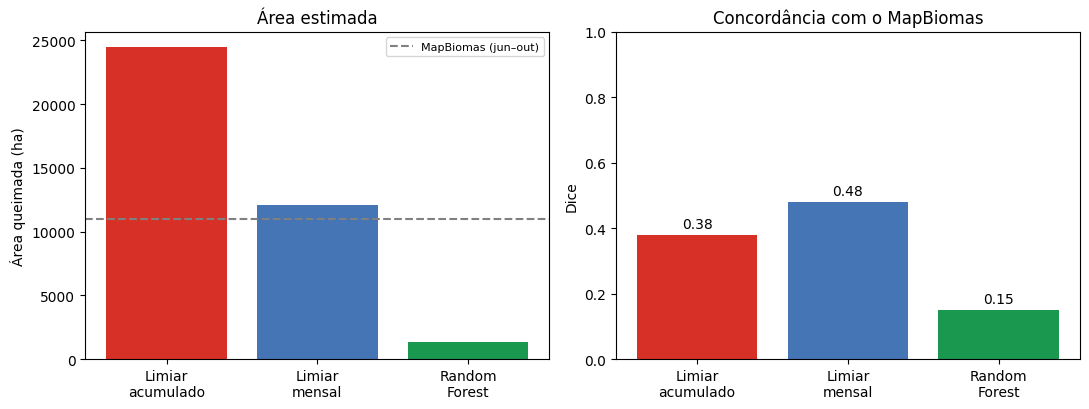

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cores = ['#d73027', '#4575b4', '#1a9850']
rotulos_curtos = ['Limiar\nacumulado', 'Limiar\nmensal', 'Random\nForest']
axes[0].bar(rotulos_curtos, comparacao['área (ha)'], color=cores)
axes[0].axhline(AREA_MB, color='gray', linestyle='--', label='MapBiomas (jun–out)')
axes[0].set_ylabel('Área queimada (ha)'); axes[0].set_title('Área estimada'); axes[0].legend(fontsize=8)
axes[1].bar(rotulos_curtos, comparacao['Dice'], color=cores)
axes[1].set_ylim(0, 1); axes[1].set_ylabel('Dice'); axes[1].set_title('Concordância com o MapBiomas')
for i, v in enumerate(comparacao['Dice']):
    axes[1].text(i, v + 0.02, f'{v:.2f}', ha='center')
plt.tight_layout()
plt.savefig(f'resultados/figuras/comparacao_tres_metodos_rf_{VARIAVEIS}.png', dpi=150)
plt.show()

## Etapa 7 — Série mensal do Random Forest

Cada pixel classificado como queimado recebe o **mês da maior queda de NBR**, como no notebook 03.

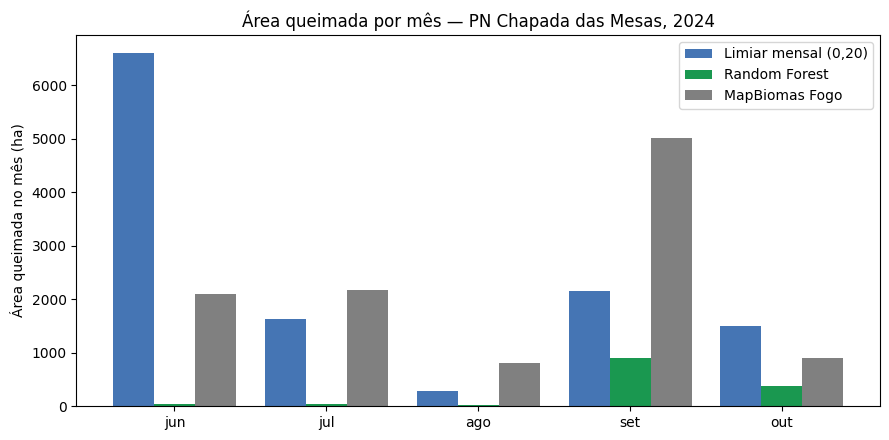

,mês,Random Forest (ha),Limiar mensal (ha),MapBiomas (ha)
0,jun,49.3,6612.1,2101.8
1,jul,41.1,1637.0,2169.8
2,ago,21.2,292.9,806.5
3,set,899.0,2152.1,5012.0
4,out,371.1,1507.8,895.7


In [17]:
pilha = ee.ImageCollection([
    dnbr_mes[m].addBands(ee.Image.constant(m).toInt().rename('mes')) for m in MESES])
mes_maior_queda = pilha.qualityMosaic('dNBR').select('mes')

def area_por_mes(img_mes, escala):
    soma = ee.Image.pixelArea().divide(1e4).addBands(img_mes).reduceRegion(
        ee.Reducer.sum().group(groupField=1, groupName='mes'), area, scale=escala, maxPixels=1e13, tileScale=4)
    return {int(g['mes']): g['sum'] for g in soma.get('groups').getInfo()}

rf_mes = area_por_mes(mes_maior_queda.updateMask(queimado_rf).rename('mes'), ESCALA)
mensal_mes = area_por_mes(mes_maior_queda.updateMask(queimado_mensal).rename('mes'), ESCALA)
mb_mes_area = area_por_mes(mb_mes.updateMask(mb_periodo).rename('mes'), 30)

serie = pd.DataFrame({
    'mês': [NOMES_MES[m] for m in MESES],
    'Random Forest (ha)': [rf_mes.get(m, 0.0) for m in MESES],
    'Limiar mensal (ha)': [mensal_mes.get(m, 0.0) for m in MESES],
    'MapBiomas (ha)': [mb_mes_area.get(m, 0.0) for m in MESES],
}).round(1)
serie.to_csv(f'resultados/tabelas/serie_mensal_tres_fontes_rf_{VARIAVEIS}.csv', index=False)

x = np.arange(len(MESES)); w = 0.27
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - w, serie['Limiar mensal (ha)'], w, color='#4575b4', label='Limiar mensal (0,20)')
ax.bar(x, serie['Random Forest (ha)'], w, color='#1a9850', label='Random Forest')
ax.bar(x + w, serie['MapBiomas (ha)'], w, color='gray', label='MapBiomas Fogo')
ax.set_xticks(x); ax.set_xticklabels(serie['mês'])
ax.set_ylabel('Área queimada no mês (ha)')
ax.set_title(f'Área queimada por mês — PN Chapada das Mesas, {ANO}')
ax.legend()
plt.tight_layout()
plt.savefig(f'resultados/figuras/serie_mensal_tres_fontes_rf_{VARIAVEIS}.png', dpi=150)
plt.show()
serie

## Etapa 8 — Mapa de concordância do Random Forest

Vermelho = os dois concordam; laranja = só o Random Forest (comissão); azul = só o MapBiomas (omissão).

Map(center=[-7.152470328340464, -47.14468685930818], controls=(WidgetControl(options=['position', 'transparent…

Salvo: resultados/figuras/mapa_concordancia_random_forest_mudanca.png


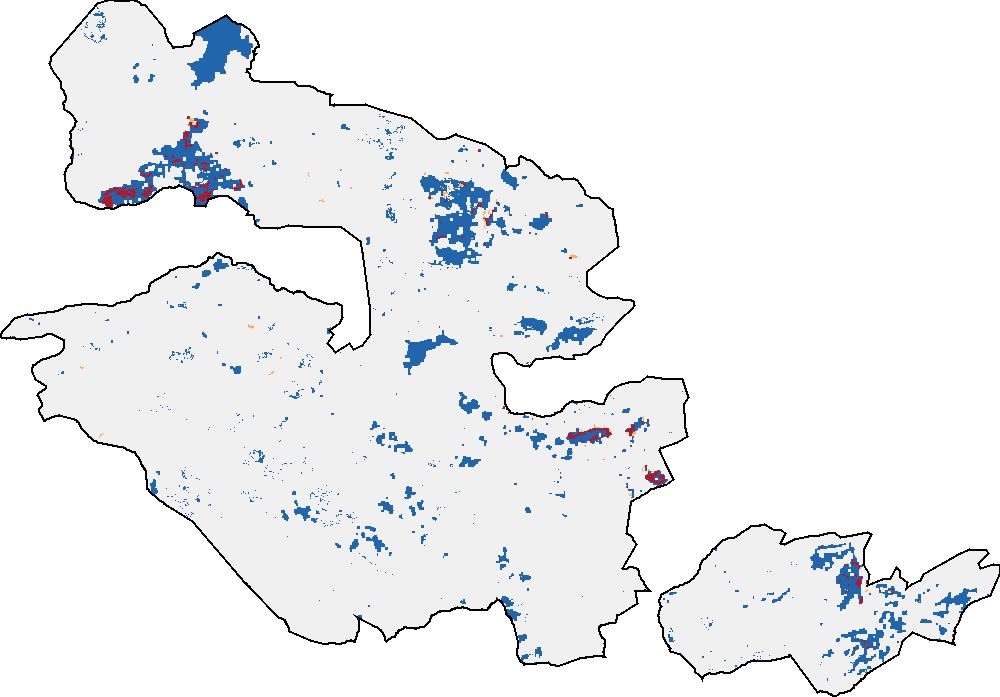

In [18]:
concordancia = queimado_rf.unmask(0).gt(0).multiply(2).add(ref).selfMask()
vis_conc = {'min': 1, 'max': 3, 'palette': ['2166ac', 'fdae61', 'b2182b']}

Map = geemap.Map(basemap='SATELLITE')
Map.centerObject(area, 10)
Map.addLayer(comps[max(MESES)], vis_falsa, 'Falsa-cor out', False)
Map.addLayer(concordancia, vis_conc, 'Concordância RF × MapBiomas')
Map.addLayer(contorno, {'palette': 'white'}, 'Limite do parque')
Map.add_legend(title='Concordância', legend_dict={
    'ambos (acerto)': 'b2182b', 'só Random Forest (comissão)': 'fdae61', 'só MapBiomas (omissão)': '2166ac'})
display(Map)

fundo = ee.Image.constant(0).visualize(palette=['f0f0f0']).clip(area)
final = fundo.blend(concordancia.visualize(**vis_conc)).blend(contorno.visualize(palette=['black']))
url = final.getThumbURL({'region': area.bounds(), 'dimensions': 1000, 'format': 'png'})
caminho = f'resultados/figuras/mapa_concordancia_random_forest_{VARIAVEIS}.png'
urllib.request.urlretrieve(url, caminho)
print('Salvo:', caminho)
display(Image(filename=caminho, width=550))

## Etapa 9 — Salvar no Drive

In [19]:
shutil.copytree('resultados', f'{PASTA}/resultados', dirs_exist_ok=True)
print('Resultados copiados para o Drive:', f'{PASTA}/resultados')

Resultados copiados para o Drive: /content/drive/MyDrive/area-queimada-chapada-mesas/resultados


## O que me mandar

O **PDF da página**, ou prints de:
1. a quantidade de amostras e a **acurácia no teste** (Etapa 4);
2. o gráfico de **importância das variáveis**;
3. a **tabela de comparação dos três métodos** e o gráfico (Etapa 6);
4. a **série mensal** (Etapa 7) e o **mapa de concordância** (Etapa 8).

---
*Problemas comuns*
- **"Nenhum polígono" ou 0 novos:** é normal se você não desenhou. O notebook usa as amostras do Drive.
- **`Computation timed out`:** troque `ESCALA = 20` por `ESCALA = 30` na Etapa 1 e rode de novo a partir dali.
- **Erro em `stratifiedSample`:** reduza `PONTOS_POR_CLASSE` para 500.